# HyperGrid Model Labs - v2
---
Klasifikasi Kondisi Permukaan Jalan & Deteksi Lubang (*Pothole Detection*) berbasis Sensor Inersial Smartphone (Akselerometer & Giroskop) - **Model Versi 2 (hype_v2)**.

### Pembaruan & Arsitektur Pipeline V2:
1. **Pembersihan Data Otomatis:** Perbaikan anomali kecepatan GPS (`speed < 0`), imputasi nilai hilang, pengurutan sekuensial timestamp, dan penanganan kondisi kendaraan diam (*stationary filtering*).
2. **Invariansi Orientasi Kausal (Zero Train-Serve Skew):** Estimasi arah gravitasi $\vec{g}(t)$ menggunakan causal Exponential Moving Average (EMA) tanpa *future lookahead*, menjamin 100% konsistensi antara data latih dan inferensi *real-time* di smartphone/web.
3. **Dekomposisi Vertikal & Horizontal:** Memisahkan getaran vertikal lubang ($a_{\text{vert}}$) dari manuver horizontal belokan/pengereman ($a_{\text{horiz}}$).
4. **Fitur Domain-Spesifik:** *Speed-Normalized Shock Ratio*, *Vertical Crest Factor*, *Vertical-to-Horizontal Shock Ratio*, dan *Zero Crossing Rate*.
5. **Stratified Group-Aware Cross-Validation:** Validasi antar-perjalanan utuh (*Unseen Trips*) dengan pembagian kelas positif merata di setiap fold.
6. **Confidence Scoring & Tiers:** Output dilengkapi skor probabilitas dan kategori keyakinan (`HIGH`, `MEDIUM`, `LOW`).
7. **Ekspor ONNX V2 Standalone:** Model mandiri siap pakai untuk Edge AI di React Native / Web.

In [1]:
# 1. Import Dependencies & Path Setup
import os
import sys
sys.path.insert(0, os.path.abspath('..'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium
from folium.plugins import MarkerCluster, HeatMap
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, precision_recall_curve, roc_curve, average_precision_score

from utils.dataset import load_raw_trips_v2
from utils.features import RoadFeatureExtractorV2
from utils.trainer import train_hypergrid_model_v2

print('HyperGrid V2 libraries and custom modules imported successfully.')

HyperGrid V2 libraries and custom modules imported successfully.


In [2]:
# 2. Memuat Data Perjalanan & Pembersihan Anomali Sensor (Pipeline V2)
trips = load_raw_trips_v2(data_dir='../data', pothole_tolerance_sec=0.6, verbose=True)
print(f'Total Sesi Perjalanan yang Dimuat: {len(trips)} trips')

Total trips V2 berhasil dimuat & dibersihkan: 20 trips
 -> Trips berisi pothole: 5 trips
 -> Trips non-pothole (Good/Bad roads): 15 trips
Total Sesi Perjalanan yang Dimuat: 20 trips


In [3]:
# 3. Ekstraksi Fitur Kausal & Dekomposisi Vertikal/Horizontal (Sliding Window V2)
extractor = RoadFeatureExtractorV2(window_size=15, step_size=3)
X, y, groups, metadata = extractor.extract_from_trips(trips)

print('=== HASIL EKSTRAKSI FITUR (v2) ===')
print(f'Matriks Fitur X : {X.shape} (47 Fitur Sinyal & Statistik)')
print(f'Label Target y  : {y.shape}')
print('\nDistribusi Label:')
print(y.value_counts())
print('\nContoh 5 Baris Pertama Fitur V2:')
X.head()

=== HASIL EKSTRAKSI FITUR (v2) ===
Matriks Fitur X : (6975, 47) (47 Fitur Sinyal & Statistik)
Label Target y  : (6975,)

Distribusi Label:
label
0    6515
1     460
Name: count, dtype: int64

Contoh 5 Baris Pertama Fitur V2:


,vert_dyn_mean,vert_dyn_std,vert_dyn_min,vert_dyn_max,vert_dyn_range,vert_dyn_rms,horiz_dyn_mean,horiz_dyn_std,horiz_dyn_min,horiz_dyn_max,...,speed_clean_std,speed_clean_min,speed_clean_max,speed_clean_range,speed_clean_rms,crest_factor_vert,vert_to_horiz_ratio,speed_norm_vert_shock,vert_zcr,is_moving
0,0.004423,0.005100,0.000002,0.016793,0.016791,0.006751,0.053453,0.022725,0.000002,0.08117,...,0.380821,0.00,1.47,1.47,0.447318,2.487108,0.206894,0.009681,0.285714,0.0
1,0.007939,0.007947,0.000048,0.026422,0.026374,0.011233,0.068103,0.019813,0.034816,0.12342,...,0.593957,0.00,1.47,1.47,0.795156,2.352029,0.214092,0.013025,0.071429,0.0
2,0.011150,0.011665,0.000048,0.043194,0.043146,0.016137,0.069092,0.021176,0.034816,0.12342,...,1.097211,0.00,3.06,3.06,1.582717,2.676614,0.349982,0.016357,0.071429,0.0
3,0.012286,0.011001,0.000048,0.043194,0.043146,0.016491,0.065901,0.025345,0.017109,0.12342,...,1.142748,0.41,3.06,2.65,2.092299,2.619087,0.349982,0.013280,0.214286,1.0
4,0.013535,0.009982,0.004519,0.043194,0.038675,0.016818,0.056758,0.029401,0.016765,0.12342,...,1.422331,0.41,4.79,4.38,2.988798,2.568184,0.349982,0.010462,0.214286,1.0


In [4]:
# 4. Training Model XGBoost V2 dengan Stratified GroupKFold & Evaluasi Unseen Trips
model_path = '../models/hype_v2.onnx'
results = train_hypergrid_model_v2(
    X=X,
    y=y,
    groups=groups,
    metadata=metadata,
    model_output_path=model_path,
    test_size=0.2,
    random_state=42,
    tune_hyperparameters=True,
)

best_model = results['model']
optimal_threshold = results['optimal_threshold']
results_df = results['results_df']

      HYPERGRID MACHINE LEARNING PIPELINE TRAINING (V2)

1. DATA SPLIT (GROUP-AWARE V2):
 - Train Samples: 4841 (from 16 trips: ['pothole_trip3', 'pothole_trip4', 'pothole_trip5', 'road_good10', 'road_good1', 'road_good2', 'road_good3', 'road_good4', 'road_good6', 'road_good8', 'road_good9', 'road_bad1', 'road_bad2', 'road_bad3', 'road_bad4', 'road_bad5'])
 - Test Samples : 2134 (from 4 trips: ['pothole_trip1', 'pothole_trip2', 'road_good5', 'road_good7'])
 - Train Pothole Ratio: 5.8% (281 lubang)
 - Test Pothole Ratio : 8.4% (179 lubang)
 - XGBoost scale_pos_weight: 16.23

2. HYPERPARAMETER TUNING VIA STRATIFIED GROUP-K-FOLD...
 - Best CV ROC-AUC: 0.9293
 - Best Parameters: {'subsample': 0.75, 'n_estimators': 100, 'min_child_weight': 3, 'max_depth': 4, 'learning_rate': 0.03, 'gamma': 0.2, 'colsample_bytree': 1.0}

3. EVALUASI TEST SET (UNSEEN TRIPS V2):
 - ROC-AUC Score: 0.8829
 - PR-AUC (Average Precision): 0.3815
 - Optimal Decision Threshold: 0.316

--- Classification Report (Optim

/var/folders/wr/yfr7rfvd10xbt_gpwcv9_ryh0000gn/T/ipykernel_99708/1724422676.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances.head(15).values, y=importances.head(15).index, palette='magma')


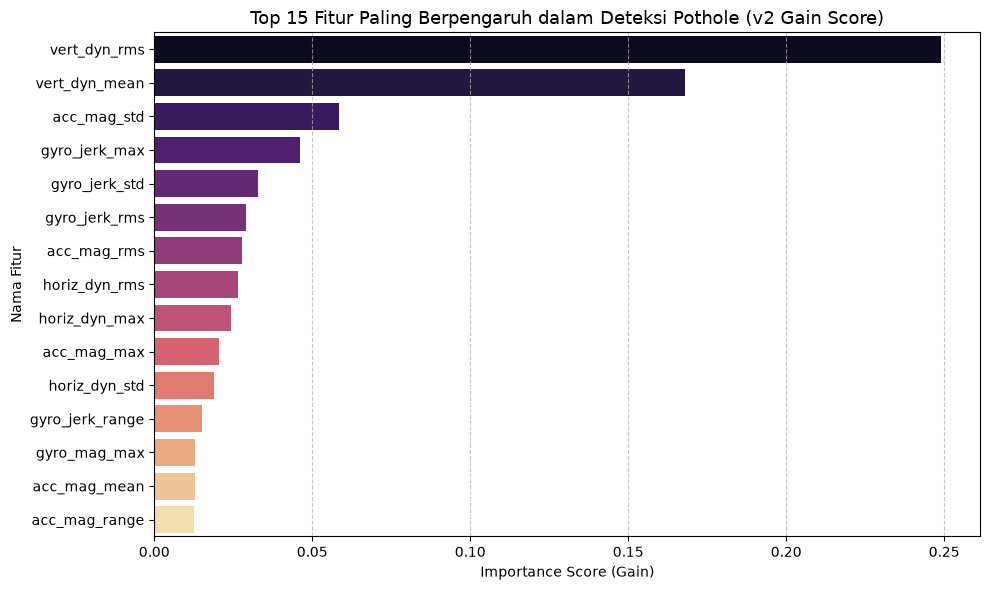

In [5]:
# 5. Visualisasi Feature Importance (Gain Score)
importances = pd.Series(best_model.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=importances.head(15).values, y=importances.head(15).index, palette='magma')
plt.title('Top 15 Fitur Paling Berpengaruh dalam Deteksi Pothole (v2 Gain Score)', fontsize=13)
plt.xlabel('Importance Score (Gain)')
plt.ylabel('Nama Fitur')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

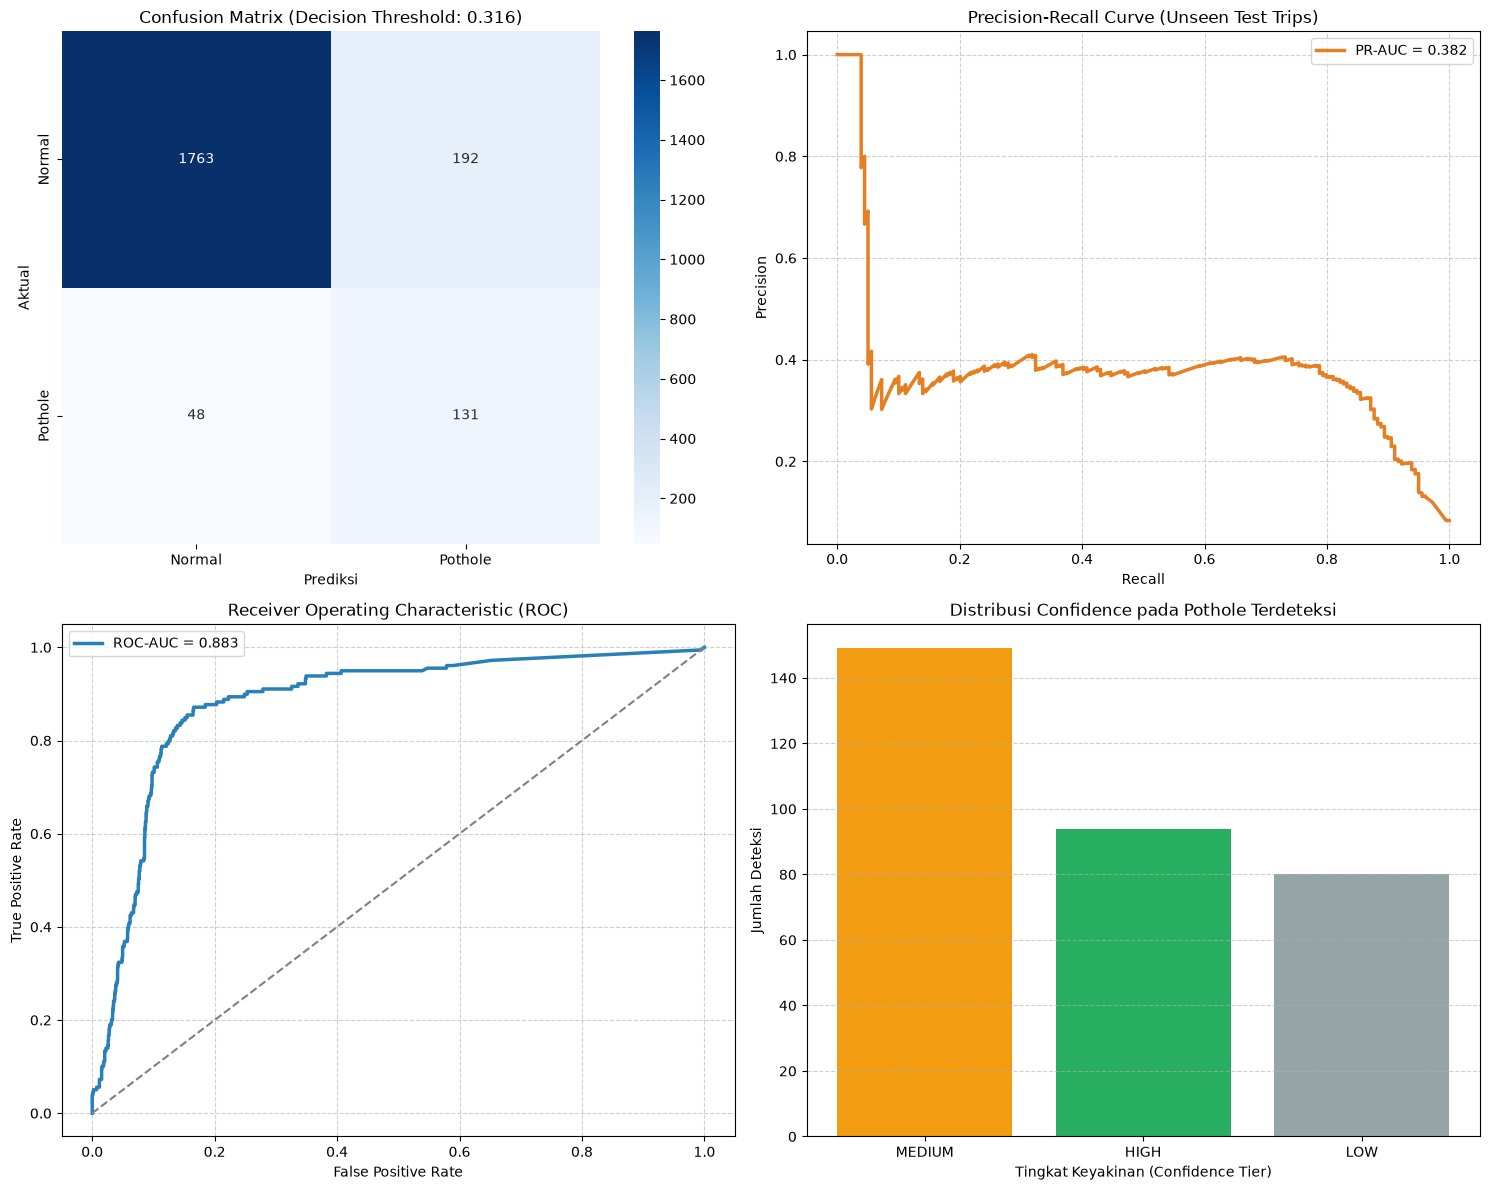

In [6]:
# 6. Visualisasi Evaluasi Model Komprehensif (Confusion Matrix, PR-Curve, ROC-Curve, & Confidence)
y_test_true = results_df['actual_label']
y_test_pred = results_df['predicted_label']
y_test_prob = results_df['pothole_probability']

fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# A. Confusion Matrix
cm = confusion_matrix(y_test_true, y_test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0, 0], xticklabels=['Normal', 'Pothole'], yticklabels=['Normal', 'Pothole'])
axes[0, 0].set_title(f'Confusion Matrix (Decision Threshold: {optimal_threshold:.3f})')
axes[0, 0].set_xlabel('Prediksi')
axes[0, 0].set_ylabel('Aktual')

# B. Precision-Recall Curve
prec, rec, _ = precision_recall_curve(y_test_true, y_test_prob)
pr_auc = average_precision_score(y_test_true, y_test_prob)
axes[0, 1].plot(rec, prec, color='#E67E22', lw=2.5, label=f'PR-AUC = {pr_auc:.3f}')
axes[0, 1].set_title('Precision-Recall Curve (Unseen Test Trips)')
axes[0, 1].set_xlabel('Recall')
axes[0, 1].set_ylabel('Precision')
axes[0, 1].grid(True, linestyle='--', alpha=0.6)
axes[0, 1].legend()

# C. ROC Curve
fpr, tpr, _ = roc_curve(y_test_true, y_test_prob)
roc_score = roc_auc_score(y_test_true, y_test_prob)
axes[1, 0].plot(fpr, tpr, color='#2980B9', lw=2.5, label=f'ROC-AUC = {roc_score:.3f}')
axes[1, 0].plot([0, 1], [0, 1], color='gray', linestyle='--')
axes[1, 0].set_title('Receiver Operating Characteristic (ROC)')
axes[1, 0].set_xlabel('False Positive Rate')
axes[1, 0].set_ylabel('True Positive Rate')
axes[1, 0].grid(True, linestyle='--', alpha=0.6)
axes[1, 0].legend()

# D. Distribusi Tingkat Confidence
conf_counts = results_df[results_df['predicted_label'] == 1]['confidence_tier'].value_counts()
colors = {'HIGH': '#27AE60', 'MEDIUM': '#F39C12', 'LOW': '#95A5A6'}
axes[1, 1].bar(conf_counts.index, conf_counts.values, color=[colors.get(k, '#3498db') for k in conf_counts.index])
axes[1, 1].set_title('Distribusi Confidence pada Pothole Terdeteksi')
axes[1, 1].set_xlabel('Tingkat Keyakinan (Confidence Tier)')
axes[1, 1].set_ylabel('Jumlah Deteksi')
axes[1, 1].grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

In [7]:
# 7. Visualisasi Peta Spasial GIS Interaktif dengan Filter Tingkat Confidence
df_map = results_df.dropna(subset=['latitude', 'longitude']).copy()
center_lat = df_map['latitude'].mean()
center_lon = df_map['longitude'].mean()

m = folium.Map(location=[center_lat, center_lon], zoom_start=14, tiles='OpenStreetMap')

# Layer Groups berdasarkan Confidence
fg_high = folium.FeatureGroup(name='⚠️ Pothole - HIGH Confidence (>=80%)', show=True).add_to(m)
fg_med = folium.FeatureGroup(name='⚠️ Pothole - MEDIUM Confidence (50-79%)', show=True).add_to(m)
fg_low = folium.FeatureGroup(name='🔍 Pothole - LOW Confidence (<50%)', show=False).add_to(m)
fg_normal = folium.FeatureGroup(name='✅ Jalan Normal', show=False).add_to(m)

for idx, row in df_map.iterrows():
    is_pothole = row['predicted_label'] == 1
    conf_tier = row['confidence_tier']
    prob = row['pothole_probability']
    
    if is_pothole:
        if conf_tier == 'HIGH':
            color = '#C0392B' # Merah tua
            target_group = fg_high
            radius = 7
        elif conf_tier == 'MEDIUM':
            color = '#E67E22' # Oranye
            target_group = fg_med
            radius = 5
        else:
            color = '#F1C40F' # Kuning
            target_group = fg_low
            radius = 4
        status = f'⚠️ POTHOLE ({conf_tier} CONFIDENCE)'
    else:
        color = '#2980B9' # Biru
        target_group = fg_normal
        radius = 2
        status = '✅ NORMAL'
        
    popup_content = f"""<b>{status}</b><hr>
    <b>Trip ID:</b> {row['trip_id']}<br>
    <b>Pothole Prob:</b> {prob:.2%}<br>
    <b>Confidence Score:</b> {row['confidence']:.2%}<br>
    <b>Peak Shock (Vertikal):</b> {row['peak_shock']:.2f} m/s²<br>
    <b>Kecepatan:</b> {row['speed']:.1f} km/h"""
    
    folium.CircleMarker(
        location=[row['latitude'], row['longitude']],
        radius=radius,
        color=color,
        fill=True,
        fill_color=color,
        fill_opacity=0.85 if is_pothole else 0.3,
        popup=folium.Popup(popup_content, max_width=280),
    ).add_to(target_group)

# Heatmap Sebaran Pothole High & Medium Confidence
pothole_coords = df_map[(df_map['predicted_label'] == 1) & (df_map['confidence_tier'].isin(['HIGH', 'MEDIUM']))][['latitude', 'longitude', 'pothole_probability']].values.tolist()
if len(pothole_coords) > 0:
    HeatMap(pothole_coords, radius=15, blur=10, name='🔥 Pothole Intensity Heatmap').add_to(m)

folium.LayerControl().add_to(m)
print('Peta spasial interaktif HyperGrid V2 berhasil dibuat!')
m

Peta spasial interaktif HyperGrid V2 berhasil dibuat!
